In [1]:
import IJulia
import Base64

# The julia kernel has built in support for Revise.jl, so this is the 
# recommended approach for long-running sessions:
# https://github.com/JuliaLang/IJulia.jl/blob/9b10fa9b879574bbf720f5285029e07758e50a5e/src/kernel.jl#L46-L51

# Users should enable revise within .julia/config/startup_ijulia.jl:
# https://timholy.github.io/Revise.jl/stable/config/#Using-Revise-automatically-within-Jupyter/IJulia-1

# clear console history
IJulia.clear_history()

fig_width = 10
fig_height = 5
fig_format = :retina
fig_dpi = 96

# no retina format type, use svg for high quality type/marks
if fig_format == :retina
  fig_format = :svg
elseif fig_format == :pdf
  fig_dpi = 96
  # Enable PDF support for IJulia
  IJulia.register_mime(MIME("application/pdf"))
end

# convert inches to pixels
fig_width = fig_width * fig_dpi
fig_height = fig_height * fig_dpi

# Intialize Plots w/ default fig width/height
try
  import Plots

  # Plots.jl doesn't support PDF output for versions < 1.28.1
  # so use png (if the DPI remains the default of 300 then set to 96)
  if (Plots._current_plots_version < v"1.28.1") & (fig_format == :pdf)
    Plots.gr(size=(fig_width, fig_height), fmt = :png, dpi = fig_dpi)
  else
    Plots.gr(size=(fig_width, fig_height), fmt = fig_format, dpi = fig_dpi)
  end
catch e
  # @warn "Plots init" exception=(e, catch_backtrace())
end

# Initialize CairoMakie with default fig width/height
try
  import CairoMakie

  # CairoMakie's display() in PDF format opens an interactive window
  # instead of saving to the ipynb file, so we don't do that.
  # https://github.com/quarto-dev/quarto-cli/issues/7548
  if fig_format == :pdf
    CairoMakie.activate!(type = "png")
  else
    CairoMakie.activate!(type = string(fig_format))
  end
  CairoMakie.update_theme!(resolution=(fig_width, fig_height))
catch e
    # @warn "CairoMakie init" exception=(e, catch_backtrace())
end
  
# Set run_path if specified
try
  run_path = "L1VzZXJzL211bGxpbnNqL0Ryb3Bib3gvVGVhY2hpbmcvRUNPTjQ1MzgvbGVjdHVyZXM="
  if !isempty(run_path)
    run_path = String(Base64.base64decode(run_path))
    cd(run_path)
  end
catch e
  @warn "Run path init:" exception=(e, catch_backtrace())
end


# emulate old Pkg.installed beahvior, see
# https://discourse.julialang.org/t/how-to-use-pkg-dependencies-instead-of-pkg-installed/36416/9
import Pkg
function isinstalled(pkg::String)
  any(x -> x.name == pkg && x.is_direct_dep, values(Pkg.dependencies()))
end

# ojs_define
if isinstalled("JSON") && isinstalled("DataFrames")
  import JSON, DataFrames
  global function ojs_define(; kwargs...)
    convert(x) = x
    convert(x::DataFrames.AbstractDataFrame) = Tables.rows(x)
    content = Dict("contents" => [Dict("name" => k, "value" => convert(v)) for (k, v) in kwargs])
    tag = "<script type='ojs-define'>$(JSON.json(content))</script>"
    IJulia.display(MIME("text/html"), tag)
  end
elseif isinstalled("JSON")
  import JSON
  global function ojs_define(; kwargs...)
    content = Dict("contents" => [Dict("name" => k, "value" => v) for (k, v) in kwargs])
    tag = "<script type='ojs-define'>$(JSON.json(content))</script>"
    IJulia.display(MIME("text/html"), tag)
  end
else
  global function ojs_define(; kwargs...)
    @warn "JSON package not available. Please install the JSON.jl package to use ojs_define."
  end
end


# don't return kernel dependencies (b/c Revise should take care of dependencies)
nothing


In [2]:
#| echo: true
#| code-fold: true
#| output: false
using Random, Statistics, StatsPlots

Base.@kwdef struct Params
    β::Float64 = 0.9      # discount factor (one period ≈ 8-9 years)
    r::Float64 = 0.3      # interest rate per period
    w::Float64 = 1.0      # price of human capital
    ψ::Float64 = 1.0      # price of investment goods
    g::Float64 = 0.35     # parental income growth, period 1 to period 2
    δ::Float64 = 0.6      # returns to skills in H'
    γ::Float64 = 0.6      # weight on early investment
    φ::Float64 = -0.5     # CES parameter: elasticity of substitution = 1/(1-φ)
    κ::Float64 = 0.0      # young parents can borrow up to κ*y2
    μ::Float64 = 1.2      # mean log ability (a scale normalization)
    ρ::Float64 = 0.4      # persistence of log ability
    σ_η::Float64 = 0.4    # sd of ability innovations
end
# copy a Params with some fields changed, e.g. Params(p; κ=0.5)
Params(p::Params; kw...) = Params(; (f => getfield(p, f) for f in fieldnames(Params))..., kw...)

skills(I1, I2, p) = (p.γ * I1^p.φ + (1 - p.γ) * I2^p.φ)^(1 / p.φ)
humancap(I1, I2, Z, p) = Z * skills(I1, I2, p)^p.δ

# Given investments, solve the savings problem in closed form.
# R1, R2: resources net of investment; E: child's earnings; b: borrowing limit for young parent
function savings(R1, R2, E, b, p)
    (; β, r) = p
    val(C1, C2, C3) = (C1 > 0 && C2 > 0 && C3 > 0) ? log(C1) + β * log(C2) + β^2 * log(C3) : -Inf
    # Case 1: neither constraint binds
    C1 = (R1 + R2 / (1 + r) + E / (1 + r)^2) / (1 + β + β^2)
    C2, C3 = β * (1 + r) * C1, (β * (1 + r))^2 * C1
    A2 = (1 + r) * (R1 - C1); Ap = (1 + r) * (R2 + A2 - C2)
    (A2 >= -b && Ap >= 0) && return val(C1, C2, C3), A2, Ap
    # Case 2: only A' ≥ 0 binds
    C1 = (R1 + R2 / (1 + r)) / (1 + β); C2 = β * (1 + r) * C1
    A2 = (1 + r) * (R1 - C1)
    (A2 >= -b && E >= β * (1 + r) * C2) && return val(C1, C2, E), A2, 0.0
    # Case 3: only A2 ≥ -b binds
    C1 = R1 + b / (1 + r)
    C2 = (R2 - b + E / (1 + r)) / (1 + β); C3 = β * (1 + r) * C2
    Ap = (1 + r) * (R2 - b - C2)
    (Ap >= 0 && C2 >= β * (1 + r) * C1) && return val(C1, C2, C3), -b, Ap
    # Case 4: both bind
    return val(R1 + b / (1 + r), R2 - b, E), -b, 0.0
end

# golden-section search for the maximum of a concave function on [lo, hi]
function golden_max(f, lo, hi; tol=1e-7)
    c = (sqrt(5) - 1) / 2
    x1, x2 = hi - c * (hi - lo), lo + c * (hi - lo)
    f1, f2 = f(x1), f(x2)
    while hi - lo > tol * (1 + abs(lo) + abs(hi))
        if f1 < f2
            lo, x1, f1 = x1, x2, f2
            x2 = lo + c * (hi - lo); f2 = f(x2)
        else
            hi, x2, f2 = x2, x1, f1
            x1 = hi - c * (hi - lo); f1 = f(x1)
        end
    end
    x = (lo + hi) / 2
    return x, f(x)
end

golden_max (generic function with 1 method)

In [3]:
#| echo: true
#| code-fold: true
#| output: false
# Solve one family's problem. T1, T2: government transfers in periods 1 and 2.
function solve_family(y1, Z, p; T1=0.0, T2=0.0)
    (; r, ψ, w, g, κ) = p
    R1, R2 = y1 + T1, (1 + g) * y1 + T2
    b = κ * (1 + g) * y1
    ϵ = 1e-10
    # period-2 problem: given I1, choose I2 (savings solved in closed form)
    function period2(I1)
        I2max = (R2 + (1 + r) * (R1 - ψ * I1)) / ψ
        return golden_max(I2 -> savings(R1 - ψ * I1, R2 - ψ * I2, w * humancap(I1, I2, Z, p), b, p)[1],
                          ϵ, I2max - ϵ)
    end
    I1, _ = golden_max(I1 -> period2(I1)[2], ϵ, (R1 + b / (1 + r)) / ψ - ϵ)
    I2, _ = period2(I1)
    H = humancap(I1, I2, Z, p)
    _, A2, Ap = savings(R1 - ψ * I1, R2 - ψ * I2, w * H, b, p)
    return (; I1, I2, H, A2, Ap,
              young_constrained = A2 <= -b + 1e-6, child_constrained = Ap <= 1e-6)
end

# Unconstrained benchmark (closed form)
function unconstrained(Z, p)
    (; r, ψ, w, δ, γ, φ) = p
    k = (γ / ((1 - γ) * (1 + r)))^(1 / (1 - φ))      # I1/I2
    θk = skills(k, 1.0, p)                           # θ when I2 = 1
    I2 = (w * Z * δ * θk^(δ - 1) * (1 - γ) * θk^(1 - φ) / ((1 + r) * ψ))^(1 / (1 - δ))
    return (; I1 = k * I2, I2)
end

# Simulate N dynasties for T generations; return the last parent-child cross-section
function simulate(p; N=3000, T=6, seed=1234)
    Random.seed!(seed)
    z = p.σ_η / sqrt(1 - p.ρ^2) * randn(N)
    y1 = [p.w * humancap(unconstrained(exp(p.μ + zi), p)..., exp(p.μ + zi), p) for zi in z]
    local out
    for t in 1:T
        zc = p.ρ * z + p.σ_η * randn(N)                       # child's ability
        sols = [solve_family(y1[i], exp(p.μ + zc[i]), p) for i in 1:N]
        out = (; y1 = copy(y1), Z = exp.(p.μ .+ zc), sols)
        y1 = [p.w * s.H for s in sols]                        # child becomes next parent
        z = zc
    end
    return out
end

ige(x, y) = cov(x, y) / var(x)
quartile_of(x) = [min(4, 1 + floor(Int, 4 * (sum(x .< xi) / length(x)))) for xi in x]

quartile_of (generic function with 1 method)

In [4]:
#| echo: false
#| output: false
p0 = Params()
base = simulate(p0)

(y1 = [0.5551408719104939, 0.722700724159864, 2.788613091861933, 2.5459996117146075, 0.898637985515772, 1.54962393120848, 1.683526201927674, 1.0886662487894414, 0.34317178654243163, 7.364033373206843  …  1.4212774318149308, 0.5166616133443604, 1.1126006731936604, 0.6540920906562168, 0.9608014163217755, 0.309647040576736, 4.528074956233339, 0.427813286731973, 1.4856305187036527, 1.4676905548289398], Z = [3.2096712541280663, 2.6152825987074535, 3.610899294654539, 4.488129130279807, 2.05031038996786, 4.076575284325114, 2.686398097624981, 4.3061900540126326, 2.8608528005402456, 10.955978574341156  …  2.9884525306297305, 1.671971261094208, 3.8638262171965776, 3.746146151341914, 2.1665199622579983, 3.1921272699180525, 6.398580775567707, 3.39605636937148, 1.9686328993601965, 3.304451905077842], sols = @NamedTuple{I1::Float64, I2::Float64, H::Float64, A2::Float64, Ap::Float64, young_constrained::Bool, child_constrained::Bool}[(I1 = 0.12616379611796813, I2 = 0.1317109109446509, H = 0.9364344410

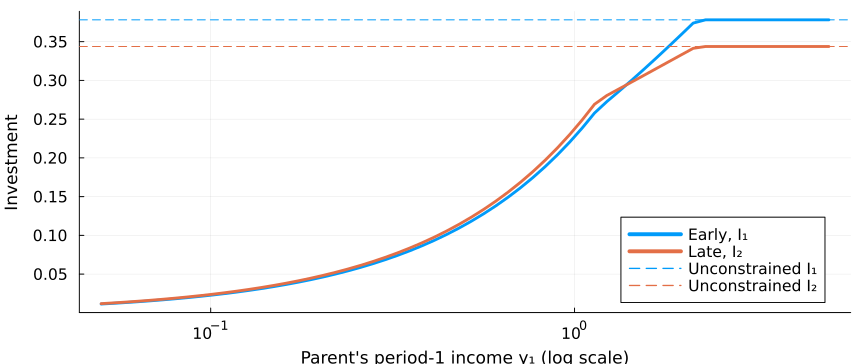

In [5]:
#| echo: true
#| code-fold: true
#| output: true
Zmed = exp(p0.μ)                                   # median ability
ygrid = exp.(range(log(0.05), log(5.0), length=60))
sol = [solve_family(y, Zmed, p0) for y in ygrid]
u = unconstrained(Zmed, p0)
plot(ygrid, [s.I1 for s in sol], xscale=:log10, label="Early, I₁", linewidth=3,
     xlabel="Parent's period-1 income y₁ (log scale)", ylabel="Investment",
     legend=:bottomright, size=(900, 380), tickfontsize=11, guidefontsize=12,
     legendfontsize=11, left_margin=4Plots.mm, bottom_margin=4Plots.mm)
plot!(ygrid, [s.I2 for s in sol], label="Late, I₂", linewidth=3)
hline!([u.I1], linestyle=:dash, color=1, label="Unconstrained I₁")
hline!([u.I2], linestyle=:dash, color=2, label="Unconstrained I₂")

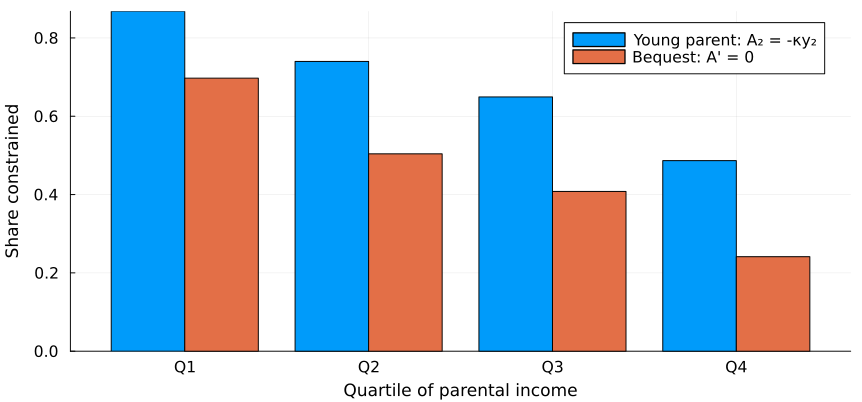

In [6]:
#| echo: true
#| code-fold: true
#| output: true
q = quartile_of(base.y1)
young = [mean(s.young_constrained for s in base.sols[q .== k]) for k in 1:4]
child = [mean(s.child_constrained for s in base.sols[q .== k]) for k in 1:4]
groupedbar([young child], bar_position=:dodge,
           xticks=(1:4, ["Q1", "Q2", "Q3", "Q4"]), xlabel="Quartile of parental income",
           ylabel="Share constrained", label=["Young parent: A₂ = -κy₂" "Bequest: A' = 0"],
           size=(900, 420), tickfontsize=11, guidefontsize=12, legendfontsize=11,
           left_margin=4Plots.mm, bottom_margin=4Plots.mm)

In [7]:
#| echo: true
#| code-fold: true
#| output: true
lp = log.(base.y1)
lc = log.([p0.w * s.H for s in base.sols])
lo = lp .< median(lp)
println("IGE (all families):        ", round(ige(lp, lc), digits=2))
println("IGE (below median income): ", round(ige(lp[lo], lc[lo]), digits=2))
println("IGE (above median income): ", round(ige(lp[.!lo], lc[.!lo]), digits=2))
println("Unconstrained benchmark:   ρ = ", p0.ρ)

IGE (all families):        0.64
IGE (below median income): 

0.68
IGE (above median income): 0.56
Unconstrained benchmark:   ρ = 0.4


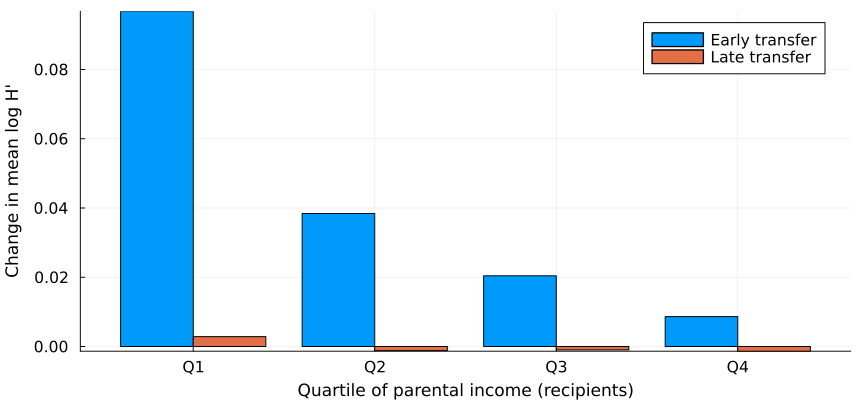

In [8]:
#| echo: true
#| code-fold: true
#| output: true
T = 0.1 * median(base.y1)
lH(v) = mean(log(s.H) for s in v)
gain = zeros(4, 2)
for k in 1:4
    idx = findall(q .== k)
    b0 = base.sols[idx]
    early = [solve_family(base.y1[i], base.Z[i], p0; T1=T) for i in idx]
    late = [solve_family(base.y1[i], base.Z[i], p0; T2=(1 + p0.r) * T) for i in idx]
    gain[k, :] = [lH(early) - lH(b0), lH(late) - lH(b0)]
end
groupedbar(gain, bar_position=:dodge, xticks=(1:4, ["Q1", "Q2", "Q3", "Q4"]),
           xlabel="Quartile of parental income (recipients)", ylabel="Change in mean log H'",
           label=["Early transfer" "Late transfer"], size=(900, 420), tickfontsize=11,
           guidefontsize=12, legendfontsize=11, left_margin=4Plots.mm, bottom_margin=4Plots.mm)

In [9]:
#| echo: true
#| code-fold: true
#| output: false
p1 = Params(p0; κ=0.5)                     # young parents can borrow up to half of y2
loose = simulate(p1)

(y1 = [0.5607256418572459, 0.7415937680697116, 2.8166668423930865, 2.5459995473455215, 0.9116510208583546, 1.5746421332932612, 1.746278946618297, 1.1246666430871926, 0.3431717876218627, 7.482924082089104  …  1.5450453787591343, 0.5166616231237326, 1.112600713365446, 0.6540921087694785, 0.9608014673794772, 0.309647080283941, 4.5736277554116445, 0.4278132837112839, 1.4856306430594994, 1.6361014912566183], Z = [3.2096712541280663, 2.6152825987074535, 3.610899294654539, 4.488129130279807, 2.05031038996786, 4.076575284325114, 2.686398097624981, 4.3061900540126326, 2.8608528005402456, 10.955978574341156  …  2.9884525306297305, 1.671971261094208, 3.8638262171965776, 3.746146151341914, 2.1665199622579983, 3.1921272699180525, 6.398580775567707, 3.39605636937148, 1.9686328993601965, 3.304451905077842], sols = @NamedTuple{I1::Float64, I2::Float64, H::Float64, A2::Float64, Ap::Float64, young_constrained::Bool, child_constrained::Bool}[(I1 = 0.1370139124013005, I2 = 0.12454687554036703, H = 0.95155

In [10]:
#| echo: true
#| code-fold: true
#| output: true
function summary_stats(out, p)
    lp = log.(out.y1); lc = log.([p.w * s.H for s in out.sols])
    return (IGE = round(ige(lp, lc), digits=2),
            share_young_constrained = round(mean(s.young_constrained for s in out.sols), digits=2),
            share_bequest_constrained = round(mean(s.child_constrained for s in out.sols), digits=2),
            early_late_ratio = round(mean(s.I1 / s.I2 for s in out.sols), digits=2))
end
s0, s1 = summary_stats(base, p0), summary_stats(loose, p1)
println(rpad("", 28), rpad("κ = 0", 10), "κ = 0.5")
for k in keys(s0)
    println(rpad(string(k), 28), rpad(s0[k], 10), s1[k])
end
println("\nUnconstrained I₁/I₂ = ", round((p0.γ / ((1 - p0.γ) * (1 + p0.r)))^(1 / (1 - p0.φ)), digits=2))

                            κ = 0     κ = 0.5
IGE                         0.64      0.64
share_young_constrained     0.69      0.0
share_bequest_constrained   0.46      0.55
early_late_ratio            1.02      1.1

Unconstrained I₁/I₂ = 1.1
